In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import shapiro
import scipy.stats as stats
from scipy.stats import levene
from scipy.stats import t

## Single Sample T-Test

In [4]:
# Assumptions for a single t-test
#  1>. Normality
#  2>. Independence
#  3>. Random Sampling
#  4>. Unknown Popluation STD

In [5]:
# Set the t-value and degrees of freedom
t_value = -1.25

# df = (n-1)
df = 24

cdf_value = t.cdf(t_value, df)
print(cdf_value)


0.1116757390828102


### Case study titanic

In [6]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

In [7]:
train.head(1)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.25,NaN,S


In [8]:
test.head(1)

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q


In [9]:
final_df = pd.concat([train,test]).sample(1309)
final_df.head(1)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
297,298,0.0,1,"Allison, Miss. Helen Loraine",female,2.0,1,2,113781,151.55,C22 C26,S


In [10]:
final_df.shape

(1309, 12)

In [11]:
pop = final_df['Age'].dropna()

In [12]:
pop

297     2.0
38     25.0
152    55.5
18     31.0
247    42.0
       ... 
883    28.0
686    14.0
183     1.0
48     60.0
132    47.0
Name: Age, Length: 1046, dtype: float64

In [13]:
sample_age = pop.sample(25).values
sample_age

array([44.  , 26.  , 26.  , 35.  , 42.  , 24.  , 32.  , 38.  , 21.  ,
       22.  ,  2.  , 59.  , 25.  ,  5.  , 27.  , 28.  , 26.  , 42.  ,
       25.  , 10.  , 36.  , 40.5 ,  0.67, 52.  , 26.  ])

In [14]:
pop.mean()

np.float64(29.881137667304014)

In [15]:
# Ho ---> The mean age is 35
# Ha ---> The mean is less than 35

In [17]:
shapiro_age = shapiro(sample_age)
print(shapiro_age)

ShapiroResult(statistic=np.float64(0.9585369861323462), pvalue=np.float64(0.3861061525018392))


In [18]:
pop_mean = 35

In [19]:
t_statistic, p_value = stats.ttest_1samp(sample_age, pop_mean)
print("t_statistic : ", t_statistic)
print("p_value : ", p_value /2)

t_statistic :  -2.234309620832598
p_value :  0.01751916608006265


In [20]:
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
else:
    print("Fail to reject the null hypothesis.")

Reject the null hypothesis.


## Independent 2 Sample t-test

EX 1>. Suppose a website owner claims that there is no difference in avg time spent on their website between desktop and mobile users.
      To test this claim, we collect data from 30 desktop users and 30 mobile users regarding the time spent on the website in minutes. 
    The sample statistcs are follows.

desktop_users:
             sample size (n1) = 30
             sample mean (mean1) = 18.5
             sample STD = 3.5

mobile_users :
             sample size (n2) = 30
             sample mean (mean2) = 14.3
             sample STD = 2.7

alpha = 0.05

Ho : ud = um
Ha : ud != um

In [21]:
# Input the data as list

desktop_users = [12,15,18,16,20,17,14,22,19,21,23,18,25,17,16,24,20,19,22,18,15,14,23,16,12,21,19,17,20,14]

mobile_users = [10,12,14,13,16,15,11,17,14,16,18,14,20,15,14,19,16,15,17,14,12,11,18,15,10,16,15,13,16,11]

In [22]:
# Perform the shapiro-Wilk test for both desktop and mobile users

shapiro_desktop = shapiro(desktop_users)
shapiro_mobile = shapiro(mobile_users)

print("Shapiro-Wilk test for Desktop_users :", shapiro_desktop)
print("Shapiro-Wilk test for Mobile_users :", shapiro_mobile)

Shapiro-Wilk test for Desktop_users : ShapiroResult(statistic=np.float64(0.9783115512411942), pvalue=np.float64(0.7791003299808725))
Shapiro-Wilk test for Mobile_users : ShapiroResult(statistic=np.float64(0.9714355768676655), pvalue=np.float64(0.5791606602037616))


In [23]:
# If the p_value from levene's test is greater than your choose significance level (alpha=0.05) , you can assume equal variances

desktop_users = [12,15,18,16,20,17,14,22,19,21,23,18,25,17,16,24,20,19,22,18,15,14,23,16,12,21,19,17,20,14]

mobile_users = [10,12,14,13,16,15,11,17,14,16,18,14,20,15,14,19,16,15,17,14,12,11,18,15,10,16,15,13,16,11]

# Perform Levene's test
levene_test = levene(desktop_users, mobile_users)
print(levene_test)

LeveneResult(statistic=np.float64(2.94395488191752), pvalue=np.float64(0.09153720526741761))


In [26]:
t_value = -5.25
df = 58

cdf_value = t.cdf(t_value, df)
print(cdf_value*2)

2.256369746933224e-06


### Case study on Titanic

In [25]:
final_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
297,298,0.0,1,"Allison, Miss. Helen Loraine",female,2.0,1,2,113781,151.550,C22 C26,S
332,1224,NaN,3,"Thomas, Mr. Tannous",male,NaN,0,0,2684,7.225,NaN,C
38,930,NaN,3,"Sap, Mr. Julius",male,25.0,0,0,345768,9.500,NaN,S
152,153,0.0,3,"Meo, Mr. Alfonzo",male,55.5,0,0,A.5. 11206,8.050,NaN,S
18,19,0.0,3,"Vander Planke, Mrs. Julius (Emelia Maria Vande...",female,31.0,1,0,345763,18.000,NaN,S


In [27]:
pop_male = final_df[final_df['Sex'] == 'male']['Age'].dropna()

pop_female = final_df[final_df['Sex'] == 'female']['Age'].dropna()

In [28]:
pop_male

38     25.0
152    55.5
247    42.0
170    61.0
433    17.0
       ... 
377    21.0
510    29.0
883    28.0
686    14.0
183     1.0
Name: Age, Length: 658, dtype: float64

In [29]:
pop_female

297     2.0
18     31.0
79     24.0
66     29.0
239    48.0
       ... 
689    15.0
554    22.0
634     9.0
48     60.0
132    47.0
Name: Age, Length: 388, dtype: float64

In [30]:
pop_male.mean()

np.float64(30.58522796352584)

In [31]:
pop_female.mean()

np.float64(28.68708762886598)

In [32]:
sample_male = pop_male.sample(25)
sample_female = pop_female.sample(25)

alpha = 0.05

In [33]:
shapiro_male = shapiro(sample_male)
shapiro_female = shapiro(sample_female)

In [34]:
levene_test = levene(sample_male, sample_female)
print(levene_test)

LeveneResult(statistic=np.float64(0.05748927990536727), pvalue=np.float64(0.8115301428338959))


In [35]:
t_statistic, p_value = stats.ttest_ind(sample_male, sample_female)
print("t_statistic :", t_statistic)
print("p_value :", p_value / 2)

t_statistic : 0.18908109088733274
p_value : 0.4254132505678551


In [36]:
alpha = 0.05
if p_value < alpha:
    print("Reject the Null Hypothesis.")
else:
    print("Fail to reject Null Hypothesis.")

Fail to reject Null Hypothesis.


## Paired 2 Sample t-test

In [39]:
before = np.array([80,92,75,68,85,78,73,90,70,88,76,84,82,77,91])

after = np.array([78,93,81,67,88,76,74,91,69,88,77,81,80,79,88])

In [40]:
differences = after - before

In [41]:
differences

array([-2,  1,  6, -1,  3, -2,  1,  1, -1,  0,  1, -3, -2,  2, -3])

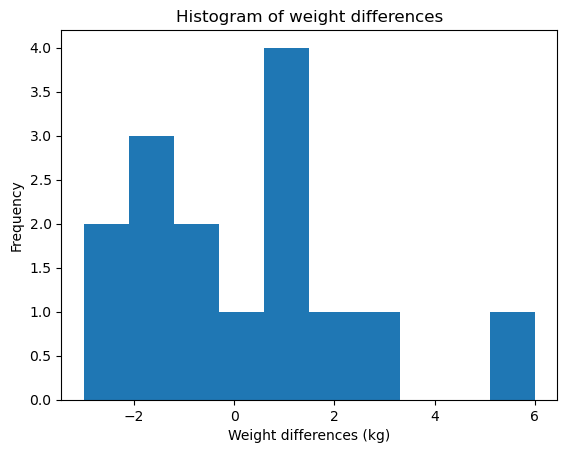

In [42]:
plt.hist(differences)
plt.title('Histogram of weight differences')
plt.xlabel('Weight differences (kg)')
plt.ylabel('Frequency')
plt.show()

In [43]:
shapiro_test = stats.shapiro(differences)
print("Shapiro-Wilk test :", shapiro_test)

Shapiro-Wilk test : ShapiroResult(statistic=np.float64(0.9220571486009436), pvalue=np.float64(0.20704778986900568))


In [45]:
mean_diff = np.mean(differences)
mean_diff

np.float64(0.06666666666666667)

In [46]:
std_diff = np.std(differences, ddof=1)
std_diff

np.float64(2.4630604269214893)

In [47]:
n = len(differences)
t_statistic = mean_diff / (std_diff / np.sqrt(n))

df = n-1

In [48]:
t_statistic

np.float64(0.10482848367219182)

In [49]:
alpha = 0.05
p_value = stats.t.cdf(t_statistic, df)

In [50]:
p_value

np.float64(0.5410005146857456)